# Volume 8, Appendix D: Projective geometry (Python companion)

Exercises first, solutions at the end. We test the theorems of Desargues and Pappus in exact arithmetic, watch Pappus fail over the quaternions, check the invariance of the cross-ratio and the harmonic construction, build finite projective planes and a deck of cards from one, count the symmetries of the Fano plane, and hunt for ordinary lines. We use `fractions`, `itertools`, `numpy` and `matplotlib`.

*Before each solution, predict what the output will look like.*

In [1]:
from fractions import Fraction as Fr
from itertools import combinations, permutations, product
import random
import numpy as np
import matplotlib.pyplot as plt
random.seed(4)
def cross(p, q):
    return (p[1] * q[2] - p[2] * q[1], p[2] * q[0] - p[0] * q[2], p[0] * q[1] - p[1] * q[0])
def det3(p, q, r):
    return sum(a * b for a, b in zip(cross(p, q), r))
rq = lambda: Fr(random.randint(-30, 30), random.randint(1, 9))
rpt = lambda: (rq(), rq(), Fr(1))

## Exercises

**P4.1 (★) Desargues and Pappus, exactly.** With rational coordinates and the cross-product formulas of Exercise 4.1, build $1000$ random Desargues configurations (Theorem 4.6) and $1000$ random Pappus configurations (Theorem 4.7), and check that the determinant of the three final points is exactly $0$.

**P4.2 (★★) Pappus over the quaternions.** Implement quaternion multiplication. Take random quaternions $a,b,c,a',b',c'$ and compute the vectors $x,y,z$ of the proof of Theorem 4.7, keeping the order of every product. Is $x-y+z=0$? Compare its third coordinate with $bb'-b'b$.

**P4.3 (★) The cross-ratio.** Check Theorem 4.9 for random Möbius maps over $\mathbb Q$ and over $\mathbb F_{101}$. Check that the $24$ orderings of four points give exactly the six values of Exercise 4.3, and find the points of $\mathbb F_{7}$ where fewer than six values occur.

**P4.4 (★) Harmonic conjugates with a straightedge.** For random quadrangles $EFGH$ (rational coordinates), build $A,B,C,D$ as in Theorem 4.12 and compute $(A,B;C,D)$ exactly. Draw one configuration.

**P4.5 (★★) Finite planes and a deck of cards.** Build $\mathbb P^2(\mathbb F_q)$ for $q=2,3,5,7$ and check Proposition 4.14. Turn $\mathbb P^2(\mathbb F_7)$ into the deck of Exercise 4.10 and check that any two cards share exactly one symbol. Then count the bijections of the Fano plane that map lines to lines by brute force over all $7!$ permutations (Exercise 4.7).

**P4.6 (★★) Ordinary lines.** An *ordinary line* of a finite set $S$ of points is a line containing exactly two of them. For the $n\times n$ grid, $n=2,\dots,7$, count the ordinary lines (Exercise 4.12 says there is at least one). Then check that in $\mathbb P^2(\mathbb F_3)$ the nine points of the affine plane $\mathbb F_3^2$ have no ordinary line.

## Solutions

### P4.1
**How to find it.** Points and lines are integer-like triples; joining and meeting are both cross products, and collinearity is a $3\times3$ determinant. Exact fractions make the check an equality, not an approximation.

In [2]:
def ext(o, a, t):    # a point on the line through o and a (affine coordinates)
    return tuple(o[i] + t * (a[i] - o[i]) for i in range(2)) + (Fr(1),)
bad = 0
for _ in range(1000):
    O, A, B, C = rpt(), rpt(), rpt(), rpt()
    A2, B2, C2 = ext(O, A, rq()), ext(O, B, rq()), ext(O, C, rq())
    P = cross(cross(B, C), cross(B2, C2)); Q = cross(cross(C, A), cross(C2, A2)); Rr = cross(cross(A, B), cross(A2, B2))
    bad += det3(P, Q, Rr) != 0
print("Desargues failures:", bad)
bad = 0
for _ in range(1000):
    U, V, W = rpt(), rpt(), rpt()
    A, B, C = [ext(U, V, rq()) for _ in range(3)]
    A2, B2, C2 = [ext(U, W, rq()) for _ in range(3)]
    X = cross(cross(A, B2), cross(A2, B)); Y = cross(cross(A, C2), cross(A2, C)); Z = cross(cross(B, C2), cross(B2, C))
    bad += det3(X, Y, Z) != 0
print("Pappus failures:", bad)

Desargues failures: 0
Pappus failures: 0


No failures in either test. (Degenerate random cases, where two of the points coincide, give a zero vector and a zero determinant, which is still "collinear"; with random rationals they essentially never occur.)

### P4.2
**How to find it.** Write a quaternion as $(w,x,y,z)$ with the Hamilton product. The proof computed $x=\bigl(a'-b',\,a-b,\,aa'-b'b\bigr)$, and the same for $y$ and $z$; with noncommuting entries we keep each product in the order it appears.

In [3]:
def qmul(p, q):
    a1, b1, c1, d1 = p; a2, b2, c2, d2 = q
    return np.array([a1*a2 - b1*b2 - c1*c2 - d1*d2, a1*b2 + b1*a2 + c1*d2 - d1*c2,
                     a1*c2 - b1*d2 + c1*a2 + d1*b2, a1*d2 + b1*c2 - c1*b2 + d1*a2])
rng = np.random.default_rng(1)
a, b, c, a2, b2, c2 = rng.integers(-5, 6, (6, 4)).astype(float)
x = (a2 - b2, a - b, qmul(a, a2) - qmul(b2, b))
y = (a2 - c2, a - c, qmul(a, a2) - qmul(c2, c))
z = (b2 - c2, b - c, qmul(b, b2) - qmul(c2, c))
third = x[2] - y[2] + z[2]
print("third coordinate of x - y + z:", third)
print("b b' - b' b:                   ", qmul(b, b2) - qmul(b2, b))
print("same quantity for commuting numbers:", 3 * 5 - 5 * 3)

third coordinate of x - y + z: [  0.  10. -30.  32.]
b b' - b' b:                    [  0.  10. -30.  32.]
same quantity for commuting numbers: 0


The first two coordinates of $x-y+z$ still cancel, but the third is $bb'-b'b$, a nonzero quaternion. The cancellation in the proof of Pappus is precisely the commutative law, as the Beauty box after Theorem 4.7 says.

### P4.3
**How to find it.** Use formula \eqref{eq:crossratio} for finite points and generic Möbius maps (avoid the pole). Over $\mathbb F_p$, division is multiplication by an inverse, `pow(x, -1, p)`.

In [4]:
def cr(a, b, c, d, inv=lambda t: 1 / t):
    return (c - a) * (d - b) * inv((c - b) * (d - a))
ok = tot = 0
for _ in range(500):
    al, be, ga, de = rq(), rq(), rq(), rq()
    if al * de == be * ga: continue
    h = lambda x: (al * x + be) / (ga * x + de)
    pts = [rq() for _ in range(4)]
    if len(set(pts)) < 4 or any(ga * x + de == 0 for x in pts): continue
    tot += 1; ok += cr(*pts) == cr(*map(h, pts))
print("rational tests passed:", ok, "of", tot)
p = 101; inv = lambda t: pow(t % p, -1, p)
ok = tot = 0
for _ in range(500):
    al, be, ga, de = (random.randrange(p) for _ in range(4))
    if (al * de - be * ga) % p == 0: continue
    pts = random.sample(range(p), 4)
    if any((ga * x + de) % p == 0 for x in pts): continue
    hp = [(al * x + be) * inv(ga * x + de) % p for x in pts]
    tot += 1; ok += cr(*pts, inv=inv) % p == cr(*hp, inv=inv) % p
print("F_101 tests passed:", ok, "of", tot)
pts = [rq() for _ in range(4)]
lam = cr(*pts)
vals = {cr(*[pts[i] for i in s]) for s in permutations(range(4))}
six = {lam, 1 / lam, 1 - lam, 1 / (1 - lam), (lam - 1) / lam, lam / (lam - 1)}
print("24 orderings give", len(vals), "values; equal to the six formulas:", vals == six)
p = 7; inv = lambda t: pow(t % p, -1, p)
for lam in range(2, p):
    s = {lam, inv(lam), (1 - lam) % p, inv(1 - lam), (lam - 1) * inv(lam) % p, lam * inv(lam - 1) % p}
    if len(s) < 6: print("F_7: lambda =", lam, "gives only", sorted(s))

rational tests passed: 483 of 483
F_101 tests passed: 481 of 481
24 orderings give 6 values; equal to the six formulas: True
F_7: lambda = 2 gives only [2, 4, 6]
F_7: lambda = 3 gives only [3, 5]
F_7: lambda = 4 gives only [2, 4, 6]
F_7: lambda = 5 gives only [3, 5]
F_7: lambda = 6 gives only [2, 4, 6]


All tests pass. In $\mathbb F_7$ the value $\lambda=-1=6$ gives the harmonic orbit $\{6,2,4\}$ ($2=1-(-1)$ and $4=\frac12$), and $\lambda=3,5$ are the roots of $\lambda^2-\lambda+1$, the equianharmonic case, with only two values $\{3,5\}$.

### P4.4
**How to find it.** Compute the four points with cross products. To get the cross-ratio on the line $AB$, write each point as $s\,a+t\,b$ (solve a small linear system) and use the coordinate $s/t$, with $A=\infty$ and $B=0$.

cross-ratios: min -1.000000000000011 max -0.999999999999987


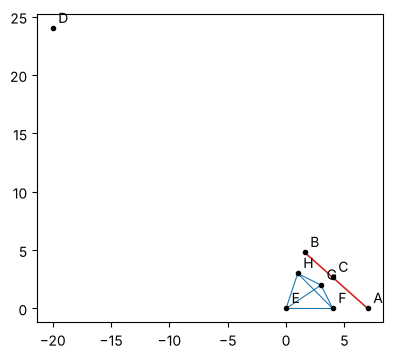

In [5]:
def coords_on(Apt, Bpt, X):   # X = s*A + t*B; return s/t (None for t=0)
    M = np.array([[float(Apt[i]), float(Bpt[i])] for i in range(3)])
    s, t = np.linalg.lstsq(M, np.array([float(v) for v in X]), rcond=None)[0]
    return None if abs(t) < 1e-12 else s / t
def harmonic(E, F, G, H):
    A = cross(cross(E, F), cross(G, H)); B = cross(cross(E, H), cross(F, G))
    AB = cross(A, B)
    Cp = cross(cross(E, G), AB); Dp = cross(cross(F, H), AB)
    c, d = coords_on(A, B, Cp), coords_on(A, B, Dp)
    return A, B, Cp, Dp, d / c   # (inf, 0; c, d) = d / c
vals = [harmonic(rpt(), rpt(), rpt(), rpt())[-1] for _ in range(1000)]
print("cross-ratios: min", min(vals), "max", max(vals))
E, F, G, H = (Fr(0), Fr(0), Fr(1)), (Fr(4), Fr(0), Fr(1)), (Fr(3), Fr(2), Fr(1)), (Fr(1), Fr(3), Fr(1))
A, B, Cp, Dp, _ = harmonic(E, F, G, H)
aff = lambda v: (float(v[0] / v[2]), float(v[1] / v[2]))
fig, ax = plt.subplots(figsize=(6, 4))
for U, V in [(E, F), (G, H), (E, H), (F, G), (E, G), (F, H)]:
    pa, pb = aff(U), aff(V); ax.plot([pa[0], pb[0]], [pa[1], pb[1]], "C0", lw=0.8)
for U, V in [(A, B)]:
    pa, pb = aff(U), aff(V); ax.plot([pa[0], pb[0]], [pa[1], pb[1]], "C3", lw=1.2)
for P_, n in zip([E, F, G, H, A, B, Cp, Dp], "EFGHABCD"):
    q = aff(P_); ax.plot(*q, "ko", ms=3); ax.annotate(n, q, xytext=(4, 4), textcoords="offset points")
ax.set_aspect("equal"); plt.show()

In the identification of the line $AB$ with $\mathbb P^1$ by $sA+tB\mapsto s/t$, we have $A=\infty$ and $B=0$, so the normalising map is $x\mapsto x/c$ and $(A,B;C,D)=d/c$. All $1000$ values are $-1$ up to rounding, for quadrangles of every shape.

### P4.5
**How to find it.** Points are the nonzero vectors of $\mathbb F_q^3$ whose first nonzero coordinate is $1$; lines are labelled the same way, and incidence is the dot product modulo $q$ (we use prime $q$).

In [6]:
def plane(q):
    pts = [v for v in product(range(q), repeat=3) if any(v) and v[next(i for i in range(3) if v[i])] == 1]
    lines = [frozenset(i for i, p in enumerate(pts) if sum(a * b for a, b in zip(l, p)) % q == 0) for l in pts]
    return pts, lines
for q in (2, 3, 5, 7):
    pts, lines = plane(q)
    print(q, "points", len(pts), "=", q * q + q + 1, "| sizes of lines", {len(L) for L in lines},
          "| lines through a point", {sum(i in L for L in lines) for i in range(len(pts))})
pts, deck = plane(7)
shared = {len(c1 & c2) for c1, c2 in combinations(deck, 2)}
print("deck of", len(deck), "cards,", len(deck[0]), "symbols each; any two share", shared)
pts2, fano = plane(2)
lineset = set(fano)
count = sum(all(frozenset(s[i] for i in L) in lineset for L in fano) for s in permutations(range(7)))
print("collineations of the Fano plane:", count)

2 points 7 = 7 | sizes of lines {3} | lines through a point {3}
3 points 13 = 13 | sizes of lines {4} | lines through a point {4}
5 points 31 = 31 | sizes of lines {6} | lines through a point {6}
7 points 57 = 57 | sizes of lines {8} | lines through a point {8}
deck of 57 cards, 8 symbols each; any two share {1}
collineations of the Fano plane: 168


The counts match Proposition 4.14: $7, 13, 31, 57$ points, lines of $q+1$ points. Any two of the $57$ cards share exactly one symbol, and the Fano plane has exactly $168$ collineations, the order of $\mathrm{PGL}_3(\mathbb F_2)$.

### P4.6
**How to find it.** Group the pairs of points by the line through them, normalised as an integer triple $(a,b,c)$ with $\gcd=1$ and a sign convention; a line with exactly two points of $S$ comes from exactly one pair.

In [7]:
from math import gcd
def norm(l):
    g = gcd(gcd(abs(l[0]), abs(l[1])), abs(l[2])); l = tuple(v // g for v in l)
    return l if next(v for v in l if v) > 0 else tuple(-v for v in l)
def ordinary(S):
    lines = {}
    for p, q in combinations(S, 2):
        lines.setdefault(norm(cross(p + (1,), q + (1,))), set()).update([p, q])
    return sum(len(v) == 2 for v in lines.values()), len(lines)
for n in range(2, 8):
    S = [(i, j) for i in range(n) for j in range(n)]
    print(n, "x", n, "grid: ordinary lines", ordinary(S)[0], "of", ordinary(S)[1])
q = 3
S = [(x, y, 1) for x in range(q) for y in range(q)]
cnt = {}
for p1, p2 in combinations(S, 2):
    L = cross(p1, p2); L = tuple(v % q for v in L)
    k = next(i for i in range(3) if L[i]); L = tuple(v * pow(L[k], -1, q) % q for v in L)
    cnt.setdefault(L, set()).update([p1, p2])
print("F_3: sizes of the lines meeting the 9 affine points:", sorted({len(v) for v in cnt.values()}))

2 x 2 grid: ordinary lines 6 of 6
3 x 3 grid: ordinary lines 12 of 20
4 x 4 grid: ordinary lines 48 of 62
5 x 5 grid: ordinary lines 108 of 140
6 x 6 grid: ordinary lines 248 of 306
7 x 7 grid: ordinary lines 428 of 536
F_3: sizes of the lines meeting the 9 affine points: [3]


The grids have many ordinary lines (the theorem only promises one; Green and Tao proved in 2013 that $n$ points not all on a line, with $n$ large enough, always have at least $n/2$ ordinary lines). Over $\mathbb F_3$, every line through two of the nine affine points contains exactly three of them: there is no ordinary line, so the order of the real numbers really is used in Kelly's proof.